# Compare reconstruction quality
Select your own compatible checkpoints/exports. All methods use one immutable validation plan,64×64 spatial queries and the declared physical times; wave u/v remain separate. No training or test-split model selection runs. With no neural checkpoint selected, the safe default evaluates **D only**. It never substitutes old smoke models.

In [1]:
from pathlib import Path
import sys, subprocess, importlib.util
PROJECT_DIR = None  # Colab: "/content/PDEep" after uploading/cloning the complete project.
INSTALL_PROJECT = False  # Colab first use: True. Local editable install: False.
if PROJECT_DIR is not None:
    project = Path(PROJECT_DIR).expanduser().resolve()
    if not (project / "pyproject.toml").is_file():
        raise RuntimeError("PROJECT_DIR must contain the complete PDEep project")
    if INSTALL_PROJECT:
        subprocess.run([sys.executable, "-m", "pip", "install", "-e", str(project)], check=True)
import pdeep, json
ROOT = Path(pdeep.__file__).resolve().parents[2]
if PROJECT_DIR is not None and ROOT != project:
    raise RuntimeError("Kernel imports another PDEep checkout; install this project and restart the kernel")
from IPython.display import display, Markdown
from pdeep.notebook_workflows import initialize
print("Project:", ROOT)


Project: /Users/nicolasackermann/Documents/ChatGPT/PDEep


In [2]:
CHECKPOINTS = {
    "A": str(ROOT / "artifacts/training_runs/A/A-468a5153d6ff51e3427cf676/inference/artifact-9c59701093d932040cdf018fd2b58d54c3b511e48aa5b07f39ef223fbb56d68e.json"),
    "C": str(ROOT / "artifacts/training_runs/C/C-d09af6be2a2774c846d91cb8/inference/artifact-b96bcfe07727658749732545e3a2ef3ce29b6da47be42d8ed238f9a325456da8.json"),
}  # e.g. {"B0":"/path/to/B0/export.json", "B1":"/path/to/B1/export.json"}
PDE_FAMILIES = ("poisson", "heat", "wave")
DEVICE = "auto"
ALLOW_PARTIAL = False  # explicit opt-in for smoke/bounded/unfinished research runs
CASE_IDS = tuple(range(50)) # (0,)  #  tiny fixed validation subset; not the untouched test split
PLAN_PATH = None  # optional independently saved matched EvaluationPlan JSON
OBSERVATION_DIAGNOSTICS = True  # optional controlled sensor perturbations
SHOW_EXECUTION_CHECKPOINTS = False  # catalog only; never auto-selects models

# Display only: one fixed case/PDE; None selects the lowest evaluated case ID.
REPRESENTATIVE_CASE_IDS = None  # e.g. {"poisson":0, "heat":0, "wave":0}

# Read-only optional display: never executes the benchmark during Notebook Run All.
SHOW_POST_TRAINING_OPTIMIZATION = True
POST_TRAINING_BENCHMARK_PATH = ROOT / "reports/post_training_optimization/result.json"


In [3]:
from pdeep.notebook_workflows import load_evaluation_selection,checkpoint_catalog
CONTEXT=initialize(ROOT,device=DEVICE)
print(CONTEXT.device_message)
CATALOG=checkpoint_catalog(ROOT,include_partial=SHOW_EXECUTION_CHECKPOINTS)
print("Available explicit candidates:",CATALOG or "No completed research checkpoint found. Train one in 02_train.ipynb; D is available now.")
METHODS=load_evaluation_selection(CONTEXT,CHECKPOINTS,allow_partial=ALLOW_PARTIAL)
for method in METHODS:
    print(method.name,"| status",method.status,"| successful updates",method.training.get("successful_updates",0),"|",method.checkpoint)


DEVICE='auto' selected mps/float32: first available: CUDA, MPS, CPU. References and B/D physics stay CPU float64. No runtime fallback.
Available explicit candidates: [{'architecture': 'C', 'status': 'trained', 'successful_updates': 10000, 'kind': 'inference_export', 'path': '/Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs/C/C-d09af6be2a2774c846d91cb8/inference/artifact-b96bcfe07727658749732545e3a2ef3ce29b6da47be42d8ed238f9a325456da8.json', 'created': '2026-11-10T17:10:10.546756+00:00'}, {'architecture': 'C', 'status': 'trained', 'successful_updates': 10000, 'kind': 'training_checkpoint', 'path': '/Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs/C/C-d09af6be2a2774c846d91cb8/checkpoints/update-00010000.json', 'created': '2026-11-10T17:10:09.682454+00:00'}, {'architecture': 'B0', 'status': 'trained', 'successful_updates': 10000, 'kind': 'inference_export', 'path': '/Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs/B0/B0-

## One common evaluation plan
The plan fixes cases, conditioning/independent held-out sensors, geometry, physical times, quantities, normalization and metric reductions for every selected method. Reusing a plan requires matching its PDE/diagnostic settings. D's point estimate is its posterior mean; deterministic neural uncertainty is unavailable.

In [4]:
from pdeep.notebook_workflows import make_evaluation_plan,evaluate_selected
PLAN,EVALUATION_CONFIG=make_evaluation_plan(CONTEXT,pdes=PDE_FAMILIES,case_ids=CASE_IDS,plan_path=PLAN_PATH,observation_diagnostics=OBSERVATION_DIAGNOSTICS)
print("Plan",PLAN.identity,"| split",PLAN.split,"| cases per PDE",{p:sum(c.pde==p for c in PLAN.cases) for p in PLAN.pdes})
print("Stationary physical time absent; dynamic times:",PLAN.dynamic_times)


Plan a90867774e59a9e1c8cc87b98c460b4874896513111a17854947593cde43fbef | split validation | cases per PDE {'poisson': 50, 'heat': 50, 'wave': 50}
Stationary physical time absent; dynamic times: (0.0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0)


In [5]:
RESULT=evaluate_selected(CONTEXT,METHODS,PLAN,EVALUATION_CONFIG)
from pdeep.evaluation_plotting import comparison_table
display(Markdown(comparison_table(RESULT)))
print("All quantity/PDE metrics and physical-case aggregation are preserved in JSON.")


| Method | Status | Updates | Macro standardized MSE | Median full inference, ms |
|---|---|---:|---:|---:|
| A | trained | 10000 | 0.0668637 | 669.073 |
| C | trained | 10000 | 0.117333 | 371.538 |
| D | exact; no training | 0 | 0.000439782 | 31.368 |

All quantity/PDE metrics and physical-case aggregation are preserved in JSON.


Representative field/uncertainty case IDs (selected by ID, not error): {'heat': 'heat/12000', 'poisson': 'poisson/12000', 'wave': 'wave/12000'}


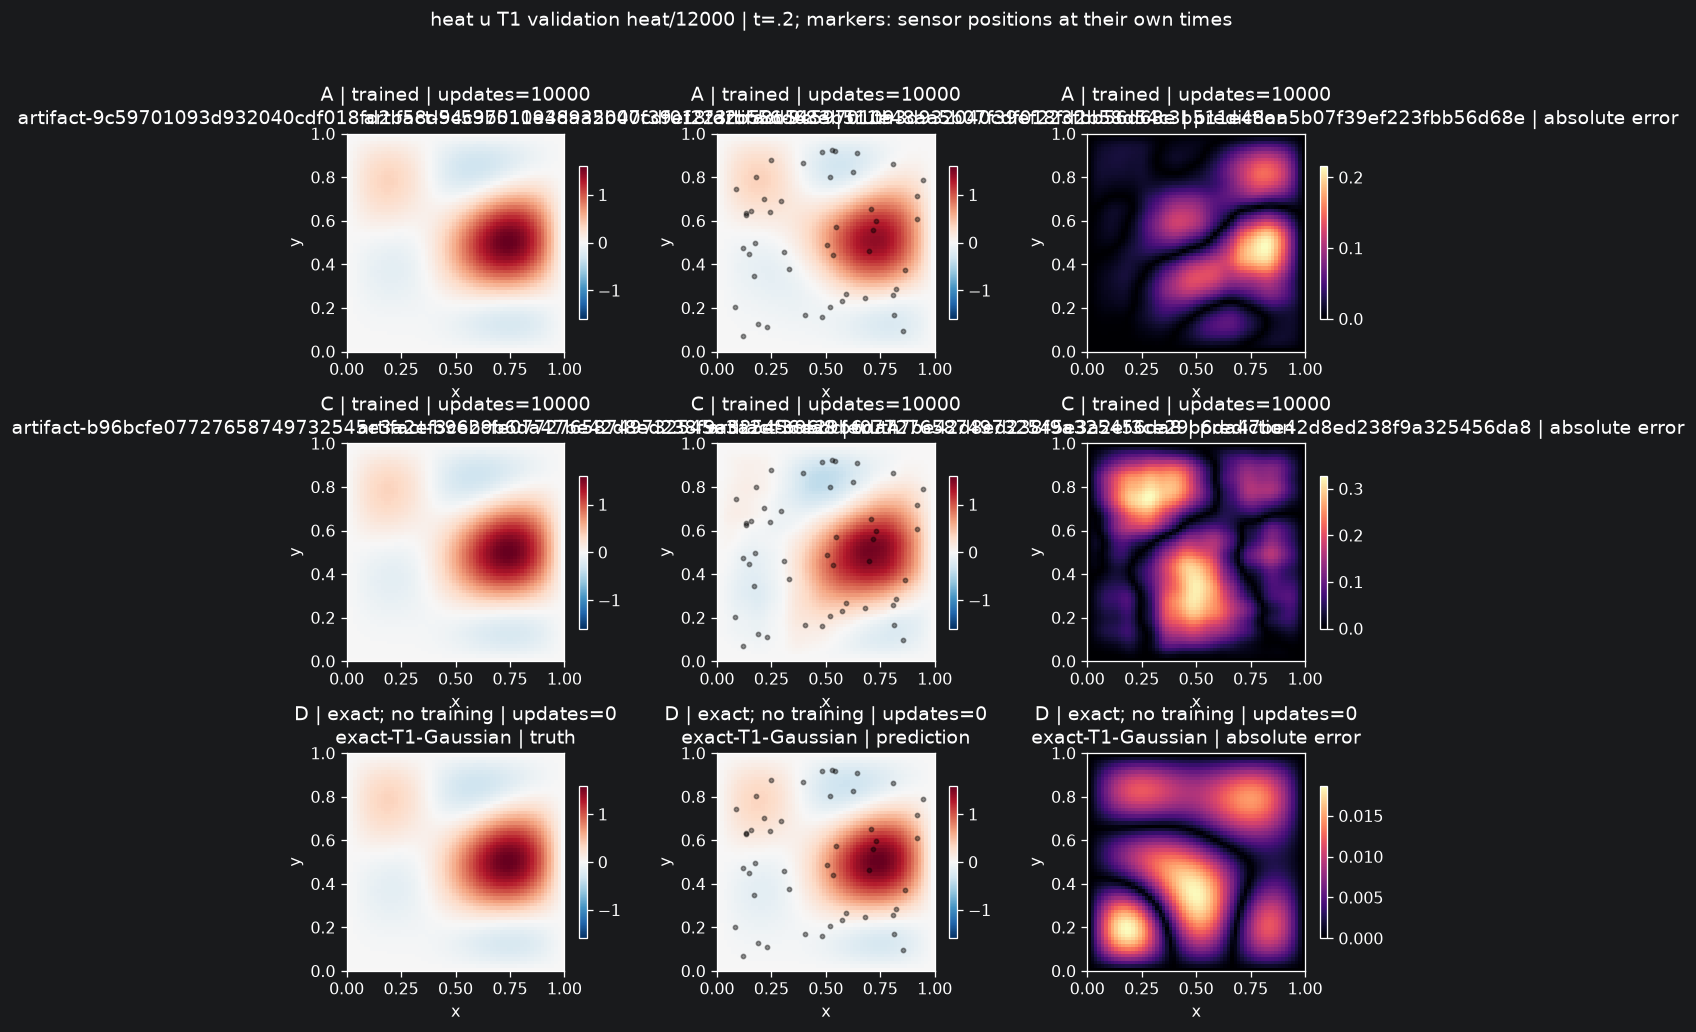

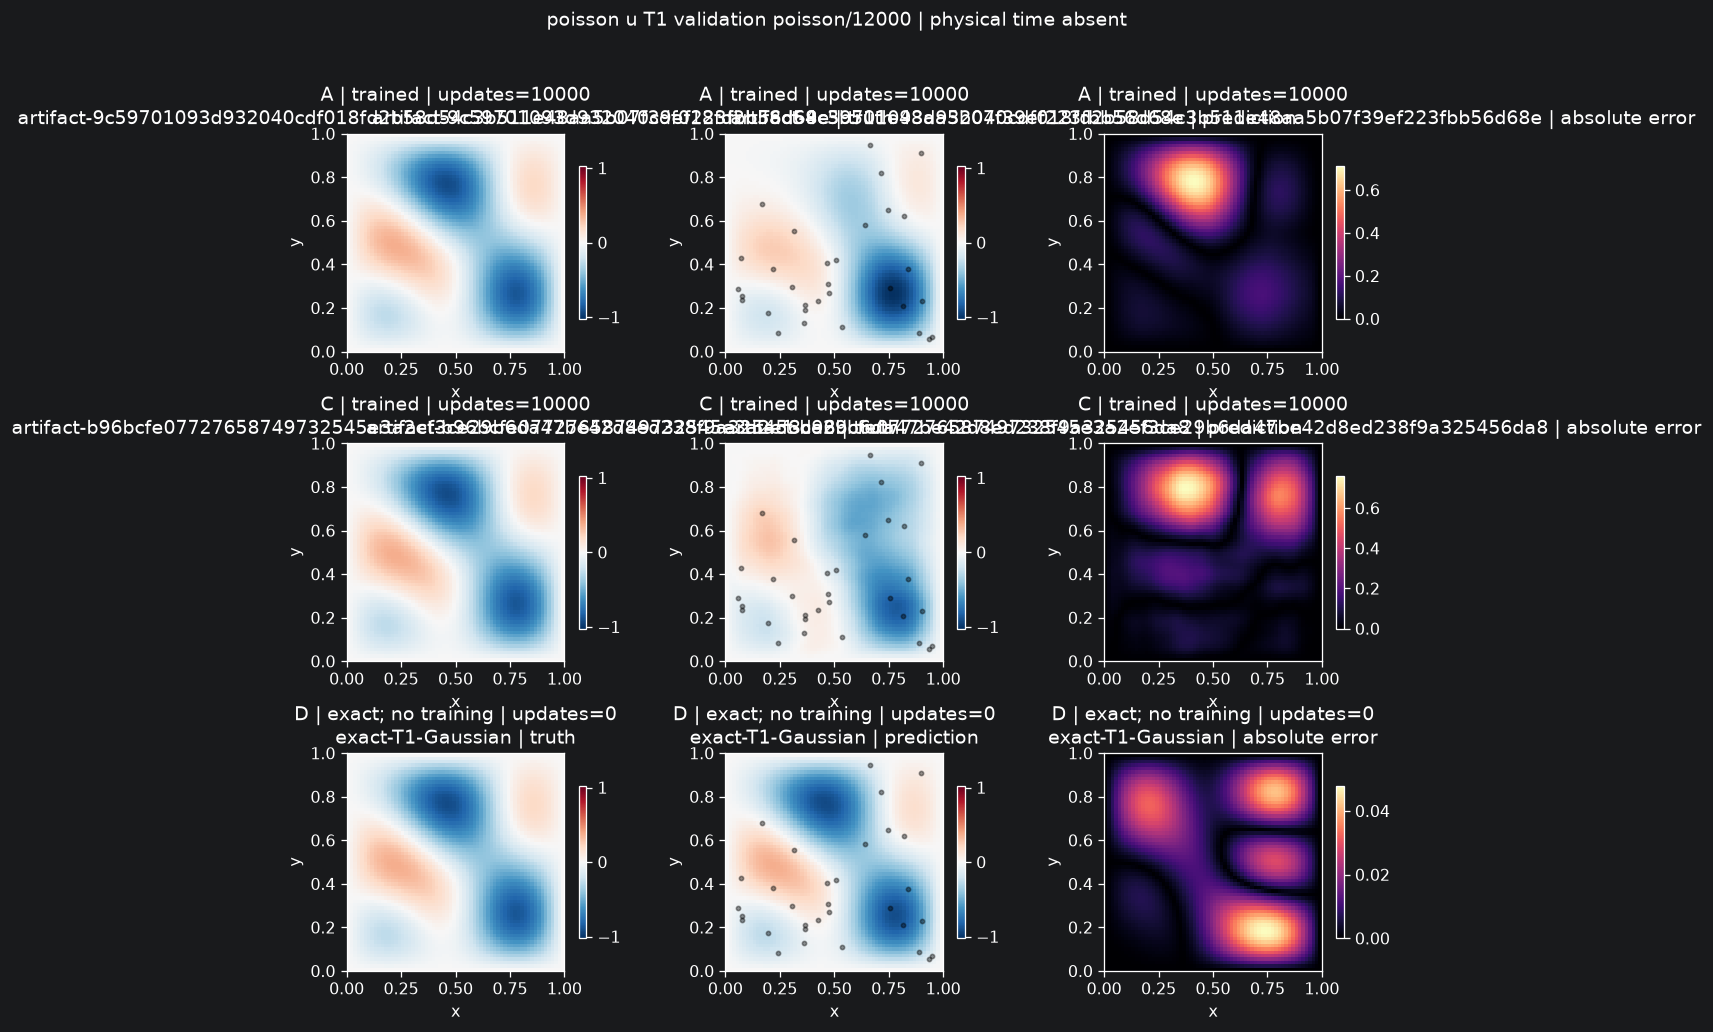

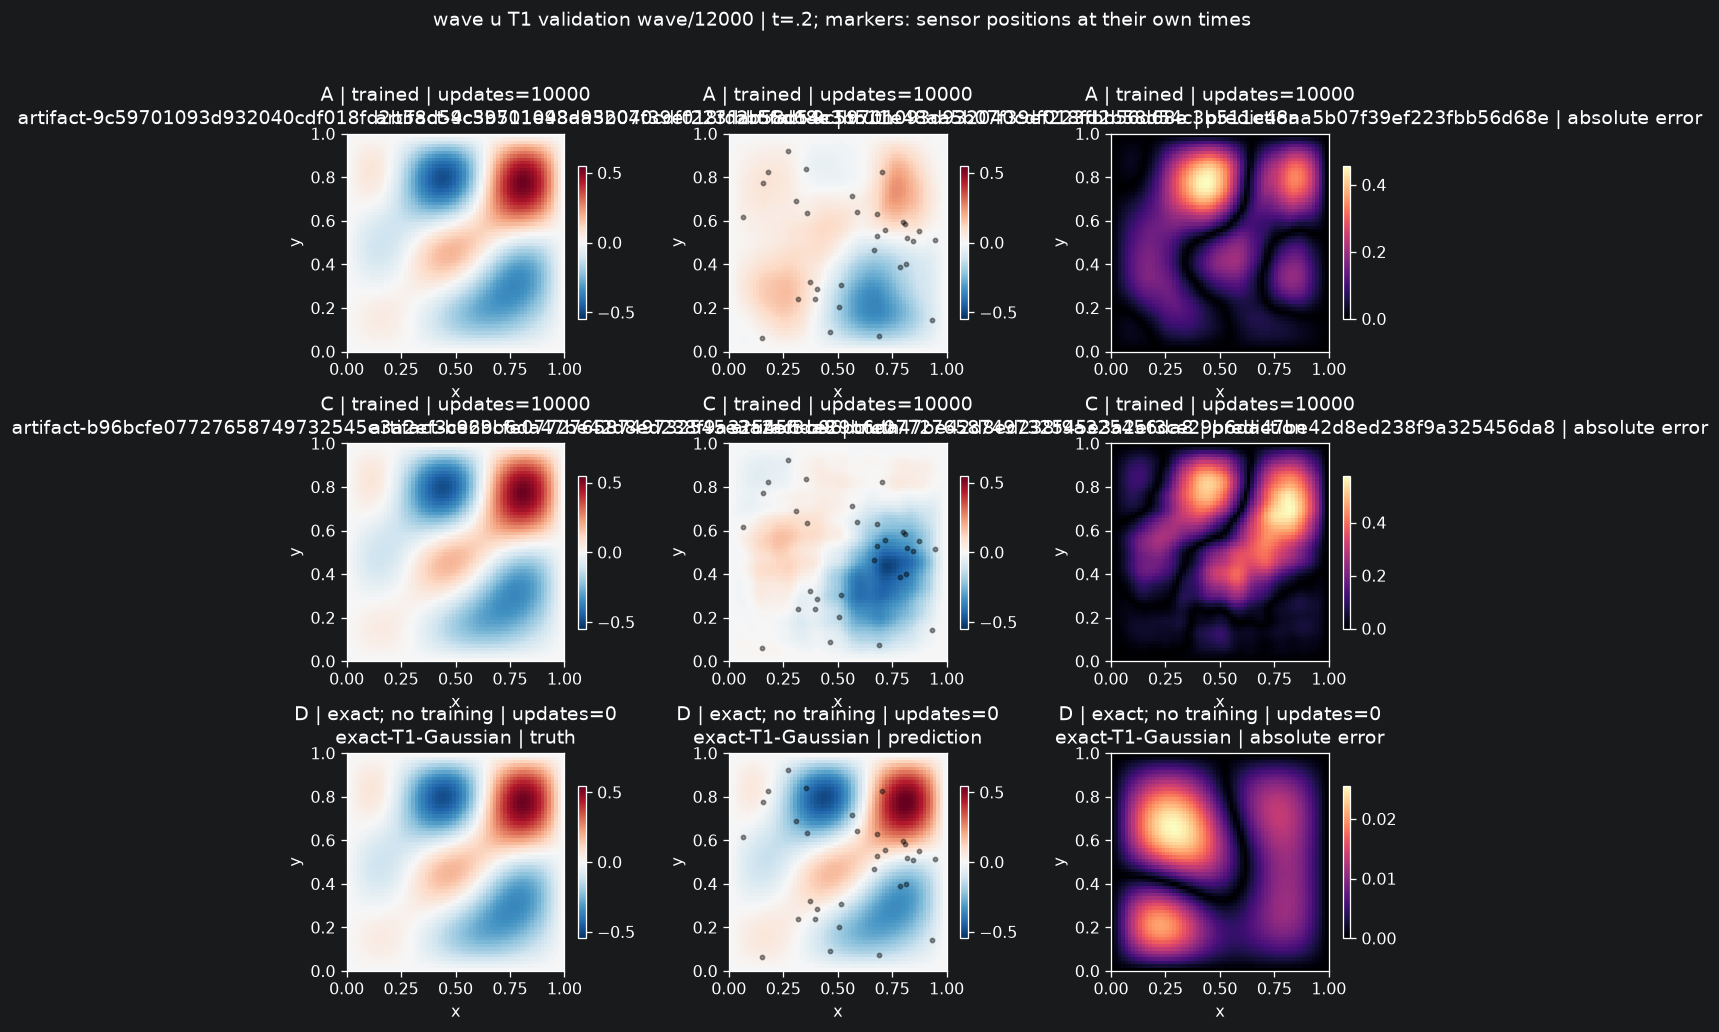

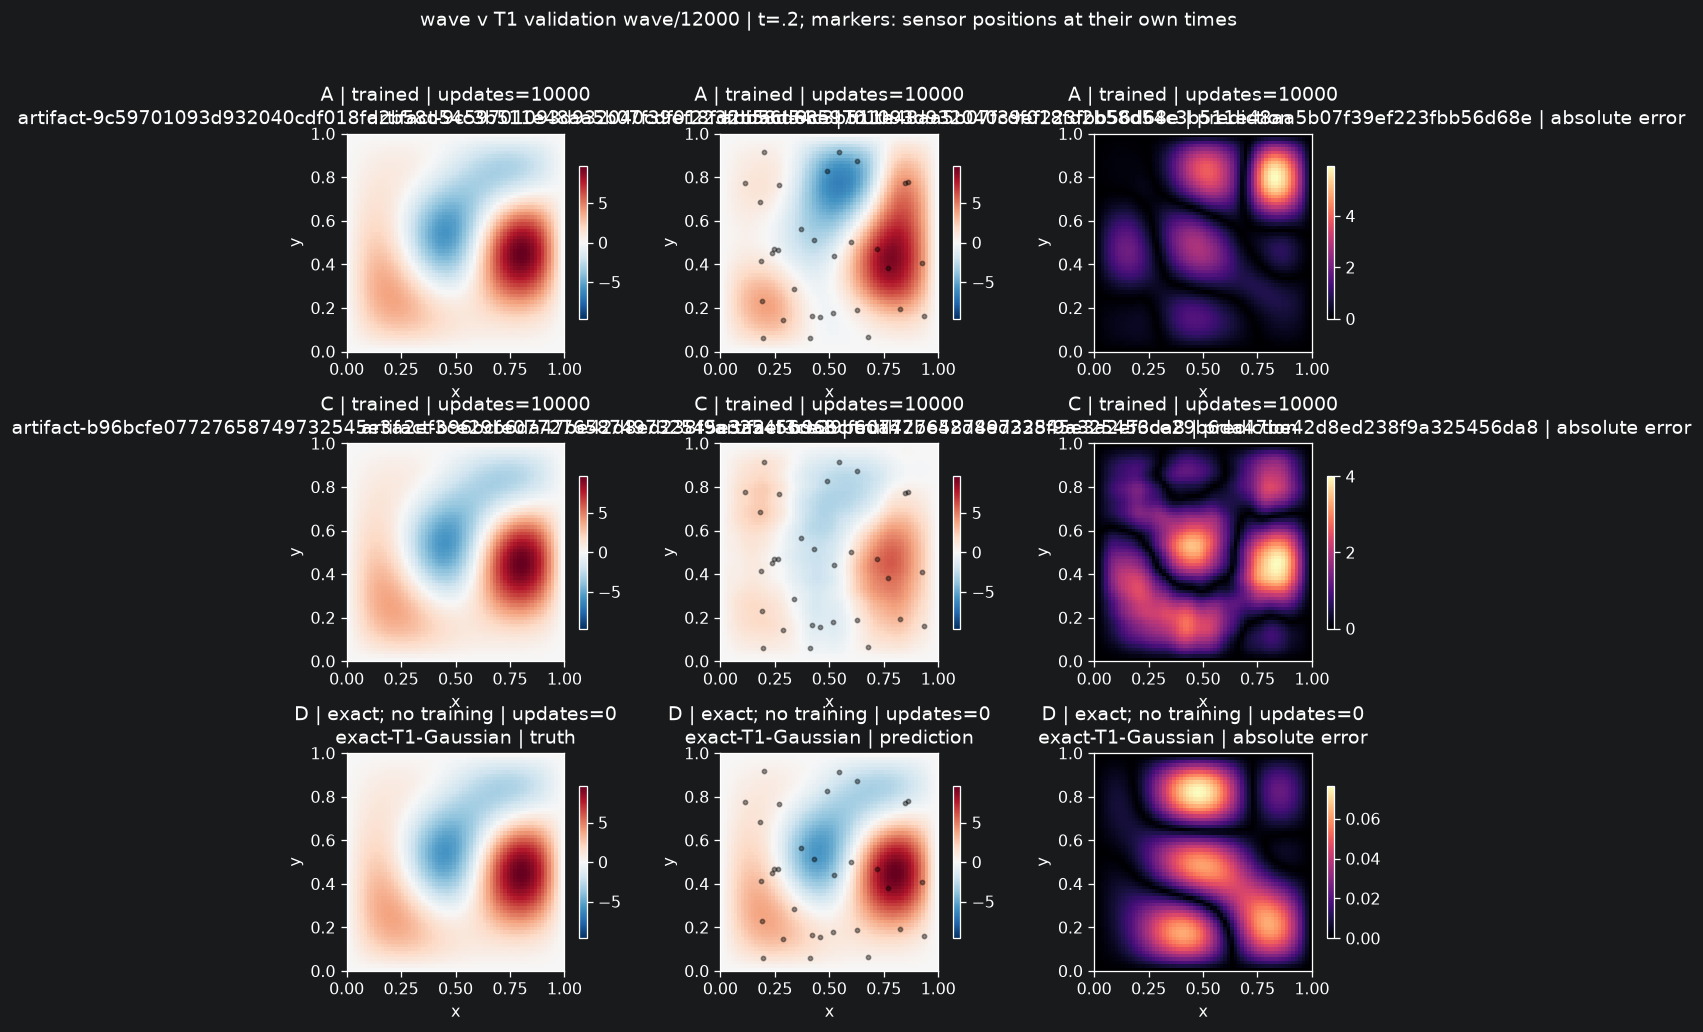

All physical cases contribute to tables and time/refinement curves; fields above are representative examples.


In [6]:
from pdeep.workflow_plotting import plot_evaluation
from pdeep.evaluation_summary import representative_cases
PLOTS=plot_evaluation(RESULT,representative_case_ids=REPRESENTATIVE_CASE_IDS)
print("Representative field/uncertainty case IDs (selected by ID, not error):",
      {p:r["case_id"] for p,r in representative_cases(RESULT["scientific"],REPRESENTATIVE_CASE_IDS).items()})
from IPython.display import Image
for path in PLOTS:
    if path.name.startswith("fields_"):display(Image(filename=str(path),width=1000))
print("All physical cases contribute to tables and time/refinement curves; fields above are representative examples.")


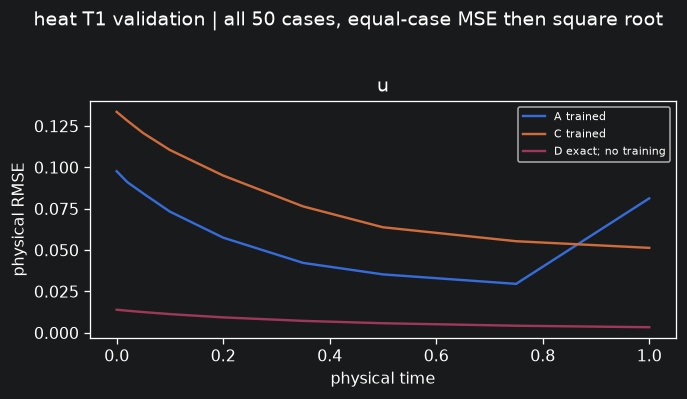

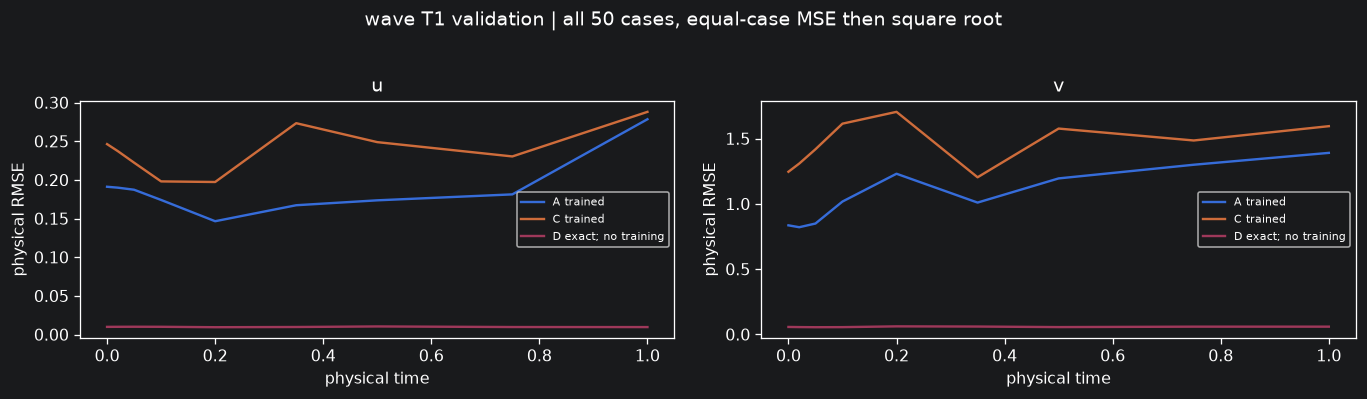

Time curves aggregate all cases using sqrt(mean MSE). Phi curves show the all-case mean and 10–90% case band.
B0/B1 have separate weights; a deterministic coefficient estimate is not a posterior sample.


In [7]:
from pdeep.evaluation_summary import refinement_summary_table
if any("refinement" in row for rows in RESULT["scientific"]["cases"].values() for row in rows):
    display(Markdown(refinement_summary_table(RESULT)))
for path in PLOTS:
    if path.name.startswith(("time_","B_refinement")):display(Image(filename=str(path),width=1000))
print("Time curves aggregate all cases using sqrt(mean MSE). Phi curves show the all-case mean and 10–90% case band.")
print("B0/B1 have separate weights; a deterministic coefficient estimate is not a posterior sample.")


In [8]:
from pdeep.evaluation_summary import physics_summary_table
display(Markdown(physics_summary_table(RESULT)))
print("Physical residuals aggregate all cases per PDE and equation component; different physical units remain separate.")
print("Strong residuals check representational consistency, not coefficient recovery. Full per-case/initial/C weak diagnostics remain in JSON.")


| Method | PDE | Cases | Equation component | Units | Physical residual RMSE | Normalized RMSE | Max boundary abs |
|---|---|---:|---:|---|---:|---:|---:|
| A | heat | 50 | 1 | U/T | 0.75416 | 0.88273 | 0 |
| A | poisson | 50 | 1 | U/L^2 | 13.944 | 0.32641 | 0 |
| A | wave | 50 | 1 | U/T | 1.296 | 0.38132 | 0 |
| A | wave | 50 | 2 | U/T^2 | 8.2952 | 0.3963 | 0 |
| C | heat | 50 | 1 | U/T | 0.30816 | 0.36069 | 0 |
| C | poisson | 50 | 1 | U/L^2 | 28.69 | 0.67163 | 0 |
| C | wave | 50 | 1 | U/T | 0.87372 | 0.25707 | 0 |
| C | wave | 50 | 2 | U/T^2 | 20.655 | 0.98677 | 0 |
| D | heat | 50 | 1 | U/T | 7.105e-17 | 8.3162e-17 | 7.74e-16 |
| D | poisson | 50 | 1 | U/L^2 | 7.7328e-15 | 1.8102e-16 | 6.85e-16 |
| D | wave | 50 | 1 | U/T | 4.8704e-16 | 1.433e-16 | 2.67e-15 |
| D | wave | 50 | 2 | U/T^2 | 4.7704e-15 | 2.279e-16 | 2.67e-15 |

Physical residuals aggregate all cases per PDE and equation component; different physical units remain separate.
Strong residuals check representational consistency, not coefficient recovery. Full per-case/initial/C weak diagnostics remain in JSON.


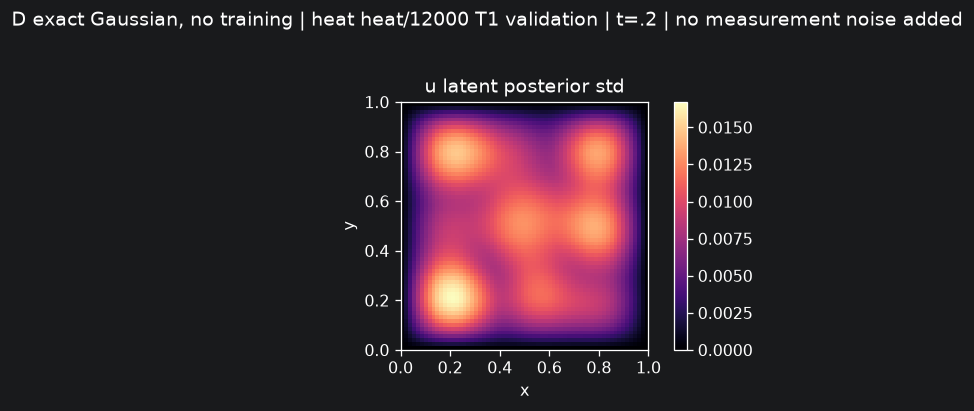

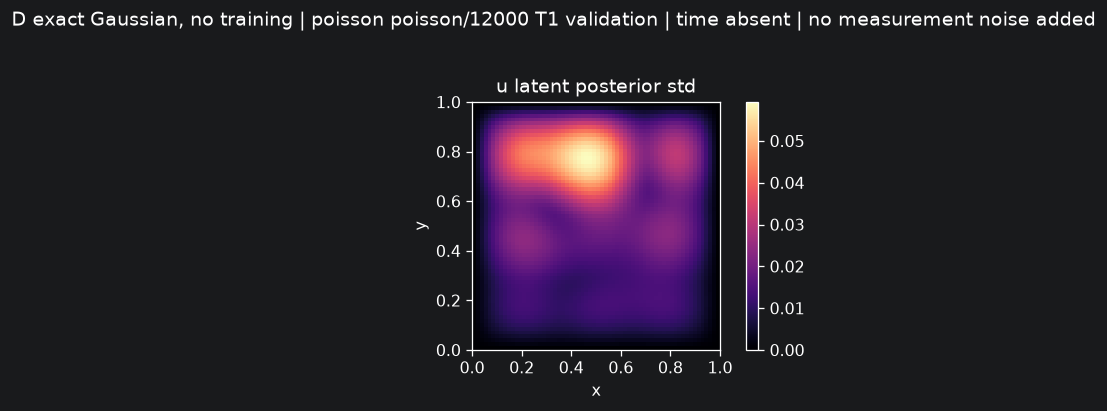

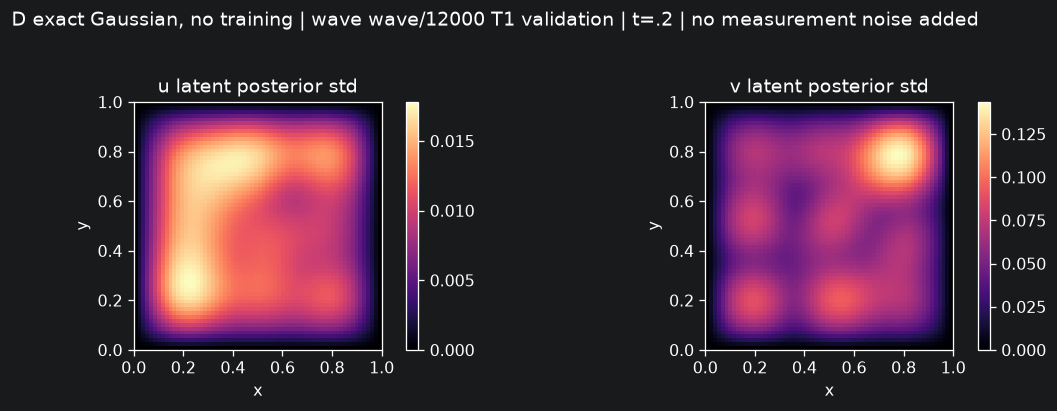

| PDE | Cases | Exact D interval | 50% coverage | 90% coverage | 95% coverage |
|---|---:|---|---:|---:|---:|
| heat | 50 | coefficients | 0.5022 | 0.8889 | 0.9378 |
| heat | 50 | held-out latent | 0.5025 | 0.9004 | 0.9562 |
| heat | 50 | held-out measurement | 0.5021 | 0.9033 | 0.9512 |
| heat | 50 | field u latent | 0.5308 | 0.8986 | 0.9495 |
| poisson | 50 | coefficients | 0.4933 | 0.9000 | 0.9489 |
| poisson | 50 | held-out latent | 0.4781 | 0.9012 | 0.9581 |
| poisson | 50 | held-out measurement | 0.4825 | 0.8925 | 0.9513 |
| poisson | 50 | field u latent | 0.5030 | 0.8882 | 0.9473 |
| wave | 50 | coefficients | 0.5289 | 0.9000 | 0.9522 |
| wave | 50 | held-out latent | 0.5247 | 0.9231 | 0.9622 |
| wave | 50 | held-out measurement | 0.4841 | 0.9009 | 0.9572 |
| wave | 50 | field u latent | 0.5532 | 0.9198 | 0.9629 |
| wave | 50 | field v latent | 0.5502 | 0.9217 | 0.9646 |

D figures: at most one fixed representative case per PDE. Coverage table: all evaluated physical cases.
Exact D latent variance excludes measurement noise; held-out measurement intervals include noise. Neural posterior uncertainty: unavailable.
Case-cluster coverage intervals and held-out log predictive densities are retained in the exported JSON.


In [9]:
from pdeep.evaluation_summary import coverage_summary_table
for path in PLOTS:
    if path.name.startswith("D_uncertainty_"):display(Image(filename=str(path),width=1000))
if "D" in RESULT["scientific"]["cases"]:
    display(Markdown(coverage_summary_table(RESULT)))
print("D figures: at most one fixed representative case per PDE. Coverage table: all evaluated physical cases.")
print("Exact D latent variance excludes measurement noise; held-out measurement intervals include noise. Neural posterior uncertainty: unavailable.")
print("Case-cluster coverage intervals and held-out log predictive densities are retained in the exported JSON.")


In [10]:
print("Exported JSON, fields and figures:",RESULT["directory"])
print("Plan:",PLAN.identity,"| scientific result:",RESULT["identity"])
print("Run metadata:",{name:{"status":r["training_status"],"updates":r["training_selection"]["successful_updates"]} for name,r in RESULT["scientific"]["methods"].items()})
print("No optimizer updates; no neural uncertainty invented; no test-set selection.")

# Separate frozen B0+Classical benchmark; validate selected weights/cases/sensors.
if SHOW_POST_TRAINING_OPTIMIZATION:
    if "B0" not in CHECKPOINTS or not POST_TRAINING_BENCHMARK_PATH.is_file():
        print("Post-training optimization: no compatible saved benchmark selected; no computation launched.")
    else:
        from pdeep.post_training_report import load_for_display,compact_table
        from pdeep.core import ValidationError
        try:
            OPTIMIZATION_BENCHMARK=load_for_display(POST_TRAINING_BENCHMARK_PATH,PLAN,CHECKPOINTS["B0"])
        except ValidationError as error:
            print("Saved post-training benchmark skipped:",error)
        else:
            display(Markdown(f"**Separate frozen B0+Classical optimization benchmark — 50 validation cases/PDE.** Neural timing device: `{OPTIMIZATION_BENCHMARK['device']}`; classical CPU64; {OPTIMIZATION_BENCHMARK['repeats']} warm repeats/case."))
            display(Markdown(compact_table(OPTIMIZATION_BENCHMARK)))
            for filename in ("accuracy_vs_iterations.png","accuracy_vs_wall_clock.png"):
                path=POST_TRAINING_BENCHMARK_PATH.parent/filename
                if path.is_file():display(Image(filename=str(path),width=1100))
            print("Warm coefficient/posterior timings include B0 preparation plus each classical tail; D includes complete posterior fit.")
            print("Classical controls and matched D use B0's existing float32 observation copy promoted to CPU64; original-float64 D is a separate control.")
            print("Full budgets, distances, gradients, operation counts, raw timing repeats and shared field-decode cost:",POST_TRAINING_BENCHMARK_PATH.parent/"report.md")


Exported JSON, fields and figures: /Users/nicolasackermann/Documents/ChatGPT/PDEep/reports/evaluation_runs/notebook-41424ededb28/a90867774e59a9e1c8cc87b98c460b4874896513111a17854947593cde43fbef
Plan: a90867774e59a9e1c8cc87b98c460b4874896513111a17854947593cde43fbef | scientific result: 83dbe53b5ccd69d40be292bbb6950984cb49160197fea8ecd3e13750462de483
Run metadata: {'A': {'status': 'trained', 'updates': 10000}, 'C': {'status': 'trained', 'updates': 10000}, 'D': {'status': 'exact; no training', 'updates': None}}
No optimizer updates; no neural uncertainty invented; no test-set selection.
Post-training optimization: no compatible saved benchmark selected; no computation launched.


To compare **B0 and B1**, train/select each independently in 02, then put both inference-export paths in `CHECKPOINTS`. Completed research models are required unless `ALLOW_PARTIAL=True`. Checkpoint selection and all per-case metrics are preserved; this notebook does not train.

Tables and time/refinement curves summarize every selected case. Field/uncertainty examples use one fixed case per PDE (lowest evaluated ID by default); `REPRESENTATIVE_CASE_IDS` changes display selection only. All per-case errors, physical/initial/weak residuals, posterior covariances, coverage intervals and predictive scores remain in JSON. Figures are written to `summary_plots/` with unique paths, avoiding repeated overwrites and repeated uncertainty displays.

For the trained B0 T1 investigation, see `reports/b0_diagnosis/diagnosis.md` and the read-only `scripts/diagnose_b0.py` runner. Multiple independent seeds are needed before drawing broader architecture comparisons.

The separate frozen **B0+Classical** benchmark appears only when its saved checkpoint/case/observation identities match this evaluation. Its two aggregate plots compare accuracy against iterations and measured coefficient/posterior cost; full results include all budgets and timing decomposition. It never trains or reruns optimization from this notebook. See `reports/post_training_optimization/report.md`.
